# Computer Vision with PyTorch: FashionMNIST

Multi-class image classification of 10 clothing categories (28x28 grayscale).
Two models are built and compared:

| Model | Architecture | Epochs | Test accuracy |
|---|---|---|---|
| `model_0` | Flatten → Linear(784, 10) → Linear(10, 10) | 3 + 3 | **84.0 %** |
| `model_1` | CNN: 2 conv blocks (Conv-ReLU-Conv-ReLU-MaxPool) + linear classifier | 3 | **87.6 %** |

*Part of my notes for [Zero to Mastery: Learn PyTorch for Deep Learning](https://www.learnpytorch.io/) (Daniel Bourke).*

## 0. Setup

In [2]:
# import pytorch
import torch
from torch import nn
# import torchvision
import torchvision
from torchvision import datasets
from torchvision.transforms import ToTensor

# import matplotlib for visualization
import matplotlib.pyplot as plt




## 1. Load the FashionMNIST dataset

In [3]:

# set the training data
train_data = datasets.FashionMNIST(root="data",train=True,transform=ToTensor(),target_transform=None,download=True)

# set testing data

test_data = datasets.FashionMNIST(root="data",train=False, transform=ToTensor(),target_transform=None,download=True)


100.0%
100.0%
100.0%
100.0%


In [4]:
# See classes
# via classes attribute you can see what is the class of the data
# we've got 10 different kinds of clothes, so this is a multi-class problem
class_name=test_data.classes
print(*class_name,sep="\n")  # '*' means unpack the list
X,y=train_data[0]    # X contains the first tensor image and y contains its label


T-shirt/top
Trouser
Pullover
Dress
Coat
Sandal
Shirt
Sneaker
Bag
Ankle boot


## 2. Visualize the data

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

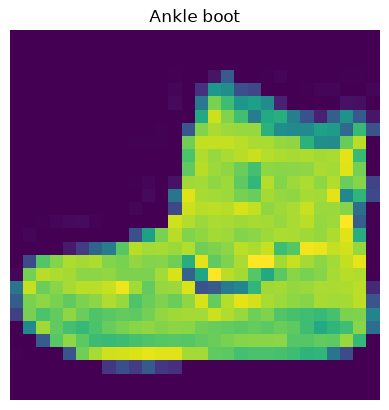

In [5]:

# Visualization
#  it expects 2D array so we need to convert the tensor to 2d by squeezing it
plt.imshow(X.squeeze())
plt.title(class_name[y])
plt.axis(False)


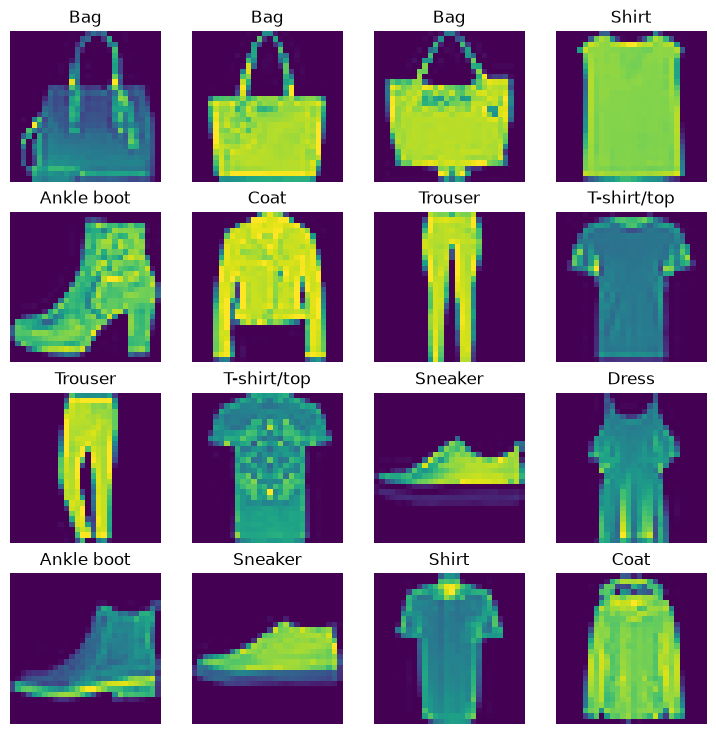

In [6]:
# plot more images

fig= plt.figure(figsize=(9,9))
row,cols=4,4

for i in range(1,16+1): # start from 1 because subplot indices start at 1
 random_idx=torch.randint(0,len(train_data),size=[1]).item()
 X,y=train_data[random_idx]
 fig.add_subplot(4,4,i)   # create subplot inside the figure
 plt.imshow(X.squeeze())
 plt.title(class_name[y])
 plt.axis(False)


## 3. Prepare DataLoaders

Batches of 32 images: 1,875 training batches and 313 test batches.

In [7]:
#Prepare DataLoader
from torch.utils.data import DataLoader
#BATCH_SIZE_
BATCH_SIZE=32
train_dataloader=DataLoader(dataset=train_data,batch_size=BATCH_SIZE,shuffle=True)

test_dataloader = DataLoader(test_data,
    batch_size=BATCH_SIZE,
    shuffle=False # don't necessarily have to shuffle the testing data
)

# Let's check out what we've created
print(f"Dataloaders: {train_dataloader, test_dataloader}")
print(f"Length of train dataloader: {len(train_dataloader)} batches of {BATCH_SIZE}")
print(f"Length of test dataloader: {len(test_dataloader)} batches of {BATCH_SIZE}")

Dataloaders: (<torch.utils.data.dataloader.DataLoader object at 0x00000289C1FDBE90>, <torch.utils.data.dataloader.DataLoader object at 0x00000289C533A720>)
Length of train dataloader: 1875 batches of 32
Length of test dataloader: 313 batches of 32


In [8]:
# train_dataloader[0]
#This will usually not work because a DataLoader is an iterator, not a list. It doesn't support indexing.
#Instead, you ask it for the next batch: batch = next(iter(train_dataloader))

In [9]:
#batch= next(iter(train_dataloader)) # now it contains 32 image and 32 labels
train_features_batch, train_labels_batch = next(iter(train_dataloader))
train_features_batch.shape, train_labels_batch.shape


(torch.Size([32, 1, 28, 28]), torch.Size([32]))

Image size: torch.Size([1, 28, 28])
Label: 9, label size: torch.Size([])


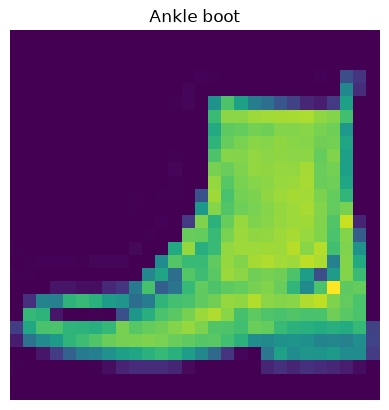

In [10]:
#show sample

plt.imshow(train_features_batch[0].squeeze())
plt.title(class_name[train_labels_batch[0]])
plt.axis(False)
print(f"Image size: {train_features_batch[0].shape}")
print(f"Label: {train_labels_batch[0]}, label size: {train_labels_batch[0].shape}")

## 4. Model 0: linear baseline

No non-linearities, so this is effectively a linear classifier. It gives a baseline to beat.

In [11]:
# Model_0
class FashionMNISTModelV0(nn.Module):
  def __init__(self,input_shape,hidden_units,output_shape): # What layers does my model have? (inside __init__)
    super().__init__()
    self.layer_stack=nn.Sequential(
      nn.Flatten(),     # neural networks like their inputs in vector form
      nn.Linear(in_features=input_shape,out_features=hidden_units),
      #nn.ReLU(),
      nn.Linear(in_features=hidden_units,out_features=output_shape),
     #nn.ReLU()


    )

  def forward(self,X):  # How should data move through those layers? (inside forward)
    return self.layer_stack(X)

In [12]:
#create an instance of our model

model_0=FashionMNISTModelV0(28*28   # one for every pixel (28x28)

                            ,10   # how many units in the hidden layer, config

                            ,len(class_name)  # has to be like numbers of output or labels

                            )

### Loss function, optimizer and accuracy metric

In [14]:
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  # Note: you need the "raw" GitHub URL for this to work
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

In [16]:
# Set up loss, accuracy and optimizer
from helper_functions import accuracy_fn
loss_fn=nn.CrossEntropyLoss()

optimizer=torch.optim.SGD(params=model_0.parameters(),lr=0.1)  # parameter >> weights and biases so update them

# you can see the parameters from here next(iter(model_0.parameters()))



In [17]:
from timeit import default_timer as timer
def print_train_time(start: float, end: float, device: torch.device = None):
    """Prints difference between start and end time.

    Args:
        start (float): Start time of computation (preferred in timeit format).
        end (float): End time of computation.
        device ([type], optional): Device that compute is running on. Defaults to None.

    Returns:
        float: time between start and end in seconds (higher is longer).
    """
    total_time = end - start
    print(f"Train time on {device}: {total_time:.3f} seconds")
    return total_time

### Training and testing loop (CPU)

In [19]:
from tqdm.auto import tqdm
torch.manual_seed(42)
epochs=3

train_loss = 0.0 # Initialize train_loss

for epoch in tqdm( range(epochs)):
    print(f"Epoch: {epoch}\n-------")
    for batch ,(X,y) in enumerate(train_dataloader):
        model_0.train()  # active training mode
        # Forward pass
        y_logits = model_0(X)
        # Calculate the loss
        loss=loss_fn(y_logits,y)
        # print(f"Batch : {batch} loss : {loss}") # Commented out to avoid excessive output
        train_loss+=loss
        # optimizer zero grad
        optimizer.zero_grad() # Using optimizer as defined in another cell
        # loss backward
        loss.backward()
        # optimizer step
        optimizer.step() # Using optimizer as defined in another cell

        if batch % 400 == 0:
            print(f"Looked at {batch * len(X)}/{len(train_dataloader.dataset)} samples")

    train_loss /= len(train_dataloader)

    # Testing loop
    test_loss,test_acc=0,0
    model_0.eval()
    with torch.inference_mode():
        for X,y in test_dataloader:
            # forward pass
            test_logits=model_0(X)
            # calculate the loss
            test_loss+=loss_fn(test_logits,y).item() # Use .item() to convert scalar tensor to Python float
            #calculate the acc
            test_acc+=accuracy_fn(y,test_logits.argmax(dim=1))

    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)
    print(f"\nTrain loss: {train_loss:.5f} | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%\n")

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
-------
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples
Looked at 51200/60000 samples


 33%|███▎      | 1/3 [00:03<00:07,  3.56s/it]


Train loss: 0.59176 | Test loss: 0.51001, Test acc: 82.16%

Epoch: 1
-------
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples
Looked at 51200/60000 samples


 67%|██████▋   | 2/3 [00:06<00:03,  3.39s/it]


Train loss: 0.47978 | Test loss: 0.48790, Test acc: 82.77%

Epoch: 2
-------
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples
Looked at 51200/60000 samples


100%|██████████| 3/3 [00:10<00:00,  3.40s/it]


Train loss: 0.45663 | Test loss: 0.47911, Test acc: 83.34%



## 5. Evaluate model 0

In [20]:
# Setup device agnostic code
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
device


'cuda'

In [21]:
torch.manual_seed(42)
def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn,device:torch.device):
    """Returns a dictionary containing the results of model predicting on data_loader.

    Args:
        model (torch.nn.Module): A PyTorch model capable of making predictions on data_loader.
        data_loader (torch.utils.data.DataLoader): The target dataset to predict on.
        loss_fn (torch.nn.Module): The loss function of model.
        accuracy_fn: An accuracy function to compare the models predictions to the truth labels.

    Returns:
        (dict): Results of model making predictions on data_loader.
    """
    loss, acc = 0, 0
    model = model.to(device) # Fix: Reassign the model to the version on the target device
    model.eval()
    with torch.inference_mode():
        for X, y in data_loader:
            X ,y = X.to(device),y.to(device)
            # Make predictions with the model
            y_pred = model(X)

            # Accumulate the loss and accuracy values per batch
            loss += loss_fn(y_pred, y)
            acc += accuracy_fn(y_true=y,
                                y_pred=y_pred.argmax(dim=1)) # For accuracy, need the prediction labels (logits -> pred_prob -> pred_labels)

        # Scale loss and acc to find the average loss/acc per batch
        loss /= len(data_loader)
        acc /= len(data_loader)

    return {"model_name": model.__class__.__name__, # only works when model was created with a class
            "model_loss": loss.item(),
            "model_acc": acc}

# Calculate model 0 results on test dataset
model_0_results = eval_model(model=model_0, data_loader=test_dataloader,
    loss_fn=loss_fn, accuracy_fn=accuracy_fn,device= device
)
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.4791141152381897,
 'model_acc': 83.33666134185303}

## 6. Device-agnostic training and testing functions

The loops are wrapped in `train_step()` and `test_step()` so any model can be trained on CPU or GPU.
`model_0` is trained for 3 more epochs on the GPU.

In [22]:
# Setup device agnostic code
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
device


'cuda'

In [23]:
from torch.autograd import backward
# Functionizing the training &testing loops

def train_step(model,data_loader,loss_fn,optimizer,accuracy_fn,device):
  train_loss,train_acc=0,0
  model.to(device)
  for batch ,(X,y) in enumerate(data_loader):
    X,y =X.to(device),y.to(device)
    # forward pass
    y_logits=model(X)

    #Calculate the loss & accuracy

    loss=loss_fn(y_logits,y)
    train_loss+=loss
    train_acc+=accuracy_fn(y,y_logits.argmax(dim=1))

    # zero grad
    optimizer.zero_grad()

    # backward
    loss.backward()

    # optimizer step

    optimizer.step()

  train_acc/=len(data_loader)
  train_loss/=len(data_loader)
  print(f" train loss : {train_loss}  train accuracy : {train_acc}\n-------")

def test_step(model,data_loader,loss_fn,accuracy_fn,device):

  test_acc,test_loss=0,0
  model.to(device)
  model.eval()
  with torch.inference_mode():
    for X,y in data_loader :
      X,y= X.to(device), y.to(device)

      test_logits=model(X)
      test_loss+=loss_fn(test_logits,y).item()
      test_acc+=accuracy_fn(y,test_logits.argmax(dim=1))

  test_loss/=len(data_loader)
  test_acc/=len(data_loader)
  print(f" test loss : {test_loss : .5f} | test accuracy : {test_acc : .5f} % ")

In [24]:
epochs =3
for epoch in tqdm(range(epochs)) :
  print(f" epoch {epoch} /n-----------------")
  train_step( model_0,train_dataloader,loss_fn,optimizer,accuracy_fn,device)
  test_step(model_0,test_dataloader,loss_fn,accuracy_fn,device)



  0%|          | 0/3 [00:00<?, ?it/s]

 epoch 0 /n-----------------
 train loss : 0.44345661997795105  train accuracy : 84.45666666666666
-------


 33%|███▎      | 1/3 [00:05<00:10,  5.38s/it]

 test loss :  0.50646 | test accuracy :  82.35823 % 
 epoch 1 /n-----------------
 train loss : 0.4347260594367981  train accuracy : 84.825
-------


 67%|██████▋   | 2/3 [00:10<00:05,  5.41s/it]

 test loss :  0.49578 | test accuracy :  82.98722 % 
 epoch 2 /n-----------------
 train loss : 0.4295485317707062  train accuracy : 85.03833333333333
-------


100%|██████████| 3/3 [00:14<00:00,  4.89s/it]

 test loss :  0.45732 | test accuracy :  84.00559 % 


In [25]:
eval_model(model_0,test_dataloader,loss_fn,accuracy_fn,device)

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.45732325315475464,
 'model_acc': 84.0055910543131}

## 7. Model 1: Convolutional Neural Network

Two convolutional blocks extract spatial features before the classifier.
`hidden_units * 36` = 10 channels × 6 × 6 feature map after two max-pool layers
(28 → 26 after the first unpadded conv → 13 → 6).

In [26]:
from numpy import block
from torch.nn.modules.linear import Linear
# Model 1: CNN (TinyVGG-style architecture)

class FashionMNISTModelV1 (nn.Module):
  def __init__(self,channels_in , hidden_units , channels_out) -> None:
     super().__init__()
     self.block_1=nn.Sequential(
         nn.Conv2d(in_channels=channels_in,out_channels=hidden_units, kernel_size=3 ,stride=1,padding=0),
         nn.ReLU(),
         nn.Conv2d(in_channels=hidden_units,out_channels=hidden_units, kernel_size=3 ,stride=1,padding=1),
         nn.ReLU(),
         nn.MaxPool2d(kernel_size=2)

     )
     self.block_2=nn.Sequential(
         nn.Conv2d(in_channels=hidden_units ,out_channels=hidden_units, kernel_size=3 ,padding=1),
         nn.ReLU(),
         nn.Conv2d(in_channels=hidden_units,out_channels=hidden_units, kernel_size=3 ,padding=1),
         nn.ReLU(),
         nn.MaxPool2d(kernel_size=2)

     )
     self.classifier_block=nn.Sequential(
         nn.Flatten(),
         nn.Linear(in_features=hidden_units*36 ,out_features=len(class_name))
     )


  def forward(self,X):
    X=self.block_1(X)
   # print(X.shape)
    X=self.block_2(X)
   # print(X.shape)
    X=self.classifier_block(X)
    #print(X.shape)

    return X



In [27]:
model_1=FashionMNISTModelV1(channels_in=1,hidden_units=10,channels_out=10)
# Setup loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer1 = torch.optim.SGD(params=model_1.parameters(),
                             lr=0.1)



In [28]:
torch.manual_seed(42)

# Measure time
from timeit import default_timer as timer
train_time_start_model_1 = timer()

# Train and test model
epochs = 3
for epoch in tqdm(range(epochs)):
    print(f"Epoch: {epoch}\n---------")
    train_step(data_loader=train_dataloader,
        model=model_1,
        loss_fn=loss_fn,
        optimizer=optimizer1,
        accuracy_fn=accuracy_fn,
        device=device
    )
    test_step(data_loader=test_dataloader,
        model=model_1,
        loss_fn=loss_fn,
        accuracy_fn=accuracy_fn,
        device=device
    )

train_time_end_model_1 = timer()
total_train_time_model_1 = print_train_time(start=train_time_start_model_1,
                                           end=train_time_end_model_1,
                                           device=device)

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
---------
 train loss : 0.6996294260025024  train accuracy : 74.14166666666667
-------


 33%|███▎      | 1/3 [00:36<01:12, 36.22s/it]

 test loss :  0.41217 | test accuracy :  85.69289 % 
Epoch: 1
---------
 train loss : 0.3815663754940033  train accuracy : 86.255
-------


 67%|██████▋   | 2/3 [00:48<00:22, 22.34s/it]

 test loss :  0.37630 | test accuracy :  86.72125 % 
Epoch: 2
---------
 train loss : 0.3418116569519043  train accuracy : 87.535
-------


100%|██████████| 3/3 [00:58<00:00, 19.46s/it]

 test loss :  0.33925 | test accuracy :  87.59984 % 
Train time on cuda: 58.390 seconds


## 8. Evaluate with a confusion matrix

Most confusion is between visually similar classes such as *Shirt*, *T-shirt/top*, *Pullover* and *Coat*.

In [31]:
# See if torchmetrics exists, if not, install it
try:
    import torchmetrics, mlxtend
    print(f"mlxtend version: {mlxtend.__version__}")
    assert int(mlxtend.__version__.split(".")[1]) >= 19, "mlxtend version should be 0.19.0 or higher"
except:
    !pip install -q torchmetrics -U mlxtend # <- Note: If you're using Google Colab, this may require restarting the runtime
    import torchmetrics, mlxtend
    print(f"mlxtend version: {mlxtend.__version__}")

mlxtend version: 0.25.0


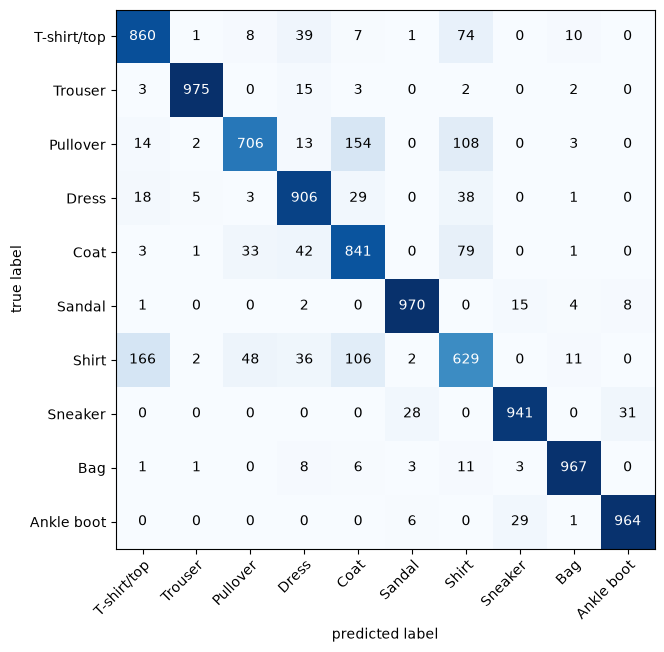

In [32]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix
import matplotlib.pyplot as plt

# 1. Make predictions on the entire test dataset
all_preds = []
all_targets = []
model_1.eval() # Set model to evaluation mode (assuming model_1 is the one you want to evaluate)
with torch.inference_mode():
    for X, y in test_dataloader:
        X, y = X.to(device), y.to(device) # Move data to target device
        y_logits = model_1(X)
        y_pred_labels = y_logits.argmax(dim=1)
        all_preds.append(y_pred_labels.cpu()) # Move predictions to CPU
        all_targets.append(y.cpu()) # Move targets to CPU

# Concatenate all predictions and targets into single tensors
all_preds_tensor = torch.cat(all_preds)
all_targets_tensor = torch.cat(all_targets)

# 2. Setup confusion matrix instance and compare predictions to targets
confmat = ConfusionMatrix(num_classes=len(class_name), task='multiclass')
confmat_tensor = confmat(preds=all_preds_tensor,
                         target=all_targets_tensor)

# 3. Plot the confusion matrix
fig, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(), # matplotlib likes working with NumPy
    class_names=class_name, # turn the row and column labels into class names
    figsize=(10, 7)
)
plt.show() # Display the plot

## Results and takeaways

- The CNN reaches **87.6 %** test accuracy after only 3 epochs (58 s on GPU), vs **84.0 %** for the linear baseline after 6 epochs.
- Convolutions exploit the 2D structure of images, which a flattened linear model cannot.
- Next steps: train longer, add more hidden units, compare optimizers (SGD vs Adam), and save the best model with `torch.save`.